# Tox21 · Member 3: Random Forest and XGBoost vs the Logistic Regression baseline

**Self-contained Google Colab notebook.** *Runtime → Run all*, then upload these files when step 1 asks:

| Upload | From |
|---|---|
| `tox21_train.csv`, `tox21_val.csv`, `tox21_test.csv` (+ optional `tox21_clean.csv`) | Member 1 (frozen scaffold split) |
| `member2_outputs.zip` | Member 2's notebook (fingerprints, descriptors, Logistic Regression results) |

**Runtime:** about 15–30 minutes on a free Colab CPU for all three feature sets. For a quick check, set `FEATURE_SETS = ["morgan"]` in the settings cell.

How the comparison is kept fair:
* **Same molecules:** Member 1's split is read and verified, never changed.
* **Same features:** this notebook loads the fingerprint and descriptor matrices **that Member 2 saved**. It does not recompute or rewrite Member 2's feature code, so all three models see identical inputs (same RDKit version too).
* **Same labels:** missing labels stay missing. Each endpoint is trained and scored only on molecules with an observed label.
* **Same metric code:** ROC-AUC and PR-AUC (average precision) come from one function. Member 2's Logistic Regression metrics are recomputed from their saved predictions with this same function, and checked against their CSV.
* **Same tuning rule:** settings are chosen on validation ROC-AUC (the team decision). The test set is used only after every configuration is frozen.

The models predict **in-vitro Tox21 assay activity**, not definitive human toxicity.

## 0. Install and import

In [1]:
import sys, subprocess
XGB_IMPORT_ERROR = None
try:
    import xgboost
except Exception:
    try:
        subprocess.check_call([sys.executable, "-m", "pip", "install", "-q", "xgboost"])
        import xgboost
    except Exception as error:          # reported below; XGBoost is NOT silently replaced
        xgboost, XGB_IMPORT_ERROR = None, repr(error)

import io, itertools, json, math, os, re, shutil, time, zipfile
from dataclasses import dataclass
from pathlib import Path
from typing import Dict, List, Optional

import joblib
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import sklearn
from scipy.stats import spearmanr
from sklearn.ensemble import RandomForestClassifier
from sklearn.impute import SimpleImputer
from sklearn.metrics import average_precision_score, roc_auc_score
from sklearn.pipeline import Pipeline

pd.set_option("display.width", 170)
pd.set_option("display.max_columns", 30)
XGB_AVAILABLE = xgboost is not None
print({"python": sys.version.split()[0], "scikit-learn": sklearn.__version__, "numpy": np.__version__,
       "pandas": pd.__version__, "xgboost": xgboost.__version__ if XGB_AVAILABLE else "NOT AVAILABLE"})
if not XGB_AVAILABLE:
    print("XGBoost could not be installed or imported:", XGB_IMPORT_ERROR)
    print("The XGBoost sections will be skipped. A possible fallback is scikit-learn's "
          "HistGradientBoostingClassifier, but it would be a different model and needs team agreement.")

{'python': '3.13.9', 'scikit-learn': '1.6.1', 'numpy': '2.5.4', 'pandas': '3.1.0', 'xgboost': '3.4.1'}


### Settings
Grids are deliberately small: **a few settings, tuned on validation**. List entries go simplest first, and on a tie the earlier entry wins.

In [2]:
SEED = 42
SELECTION_METRIC = "roc_auc"          # team decision: choose on validation ROC-AUC (PR-AUC breaks ties)
FEATURE_SETS = ["morgan", "descriptors", "morgan+descriptors"]
N_JOBS = -1                           # all CPU cores; results do not depend on this

TASKS = ["NR-AR", "NR-AR-LBD", "NR-AhR", "NR-Aromatase", "NR-ER", "NR-ER-LBD",
         "NR-PPAR-gamma", "SR-ARE", "SR-ATAD5", "SR-HSE", "SR-MMP", "SR-p53"]
SPLITS = ["train", "val", "test"]
FOLDER = {"morgan": "morgan", "descriptors": "descriptors", "morgan+descriptors": "morgan_descriptors"}

# Random Forest: fixed settings + the small grid searched on validation
RF_BASE = {"n_estimators": 300, "max_depth": None, "max_features": "sqrt",
           "min_samples_leaf": 1, "class_weight": None}
RF_GRID = {"min_samples_leaf": [1, 3], "class_weight": [None, "balanced_subsample"]}
RF_FALLBACK = {"min_samples_leaf": 1, "class_weight": "balanced_subsample"}   # only if validation has one class

# XGBoost: fixed settings + grid. scale_pos_weight "balanced" means n_negative / n_positive of the endpoint's training labels.
XGB_BASE = {"n_estimators": 300, "max_depth": 6, "learning_rate": 0.1, "subsample": 0.8,
            "colsample_bytree": 0.5, "min_child_weight": 1, "reg_lambda": 1.0, "scale_pos_weight": 1.0,
            "tree_method": "hist", "eval_metric": "logloss"}
XGB_GRID = {"max_depth": [3, 6], "learning_rate": [0.05, 0.1],
            "scale_pos_weight": [1.0, "balanced"], "n_estimators": [100, 300]}
XGB_FALLBACK = {"max_depth": 6, "learning_rate": 0.1, "n_estimators": 300, "scale_pos_weight": "balanced"}

RESULTS_DIR, MODELS_DIR = Path("results"), Path("models")

## 1. Get the inputs
In Colab an upload button appears. Select the Member 1 CSVs **and** `member2_outputs.zip` together. Zip files are extracted automatically.
*Alternative:* put the files in a Google Drive folder, mount Drive, and set `INPUT_DIR` to that folder.

In [3]:
try:
    from google.colab import files as colab_files
    IN_COLAB = True
except ImportError:
    IN_COLAB = False

INPUT_DIR = Path("/content/inputs") if IN_COLAB else Path(os.environ.get("TOX21_INPUT_DIR", "inputs"))
INPUT_DIR.mkdir(parents=True, exist_ok=True)


def safe_extract(zip_path: Path, target: Path) -> None:
    """Extract a zip, refusing entries that would land outside the target folder."""
    target = target.resolve()
    with zipfile.ZipFile(zip_path) as archive:
        for name in archive.namelist():
            destination = (target / name).resolve()
            if destination != target and target not in destination.parents:
                raise ValueError(f"Unsafe path in {zip_path.name}: {name}")
        archive.extractall(target)


def find_input(name: str, required: bool = True) -> Optional[Path]:
    """Locate exactly one file called `name` under INPUT_DIR (ignoring macOS __MACOSX folders)."""
    matches = sorted(p for p in INPUT_DIR.rglob(name) if "__MACOSX" not in p.parts)
    if len(matches) > 1:
        raise RuntimeError(f"Found {len(matches)} copies of {name}; keep only one: {matches}")
    if not matches and required:
        raise FileNotFoundError(f"{name} not found under {INPUT_DIR.resolve()}")
    return matches[0] if matches else None


NEEDED = ["tox21_train.csv", "tox21_val.csv", "tox21_test.csv", "morgan_r2_b2048_train.npz", "lr_metrics.csv"]


def extract_zips() -> None:
    for zip_path in INPUT_DIR.glob("*.zip"):
        target = INPUT_DIR / zip_path.stem
        if not target.exists():
            safe_extract(zip_path, target)


extract_zips()
if IN_COLAB and any(find_input(n, required=False) is None for n in NEEDED):
    print("Upload: tox21_train.csv, tox21_val.csv, tox21_test.csv (optional tox21_clean.csv) and member2_outputs.zip")
    for name, content in colab_files.upload().items():
        clean_name = re.sub(r" \(\d+\)(?=\.\w+$)", "", Path(name).name)   # "file (1).csv" -> "file.csv"
        (INPUT_DIR / clean_name).write_bytes(content)
    extract_zips()

SPLIT_FILES = {s: find_input(f"tox21_{s}.csv") for s in SPLITS}
CLEAN_FILE = find_input("tox21_clean.csv", required=False)
MEMBER2_DIR = find_input("morgan_r2_b2048_train.npz").parent.parent
LR_DIR = MEMBER2_DIR / "results" / "logistic_regression"
for needed in [LR_DIR / "lr_metrics.csv", MEMBER2_DIR / "features" / "descriptors_train.npz"]:
    if not needed.is_file():
        raise FileNotFoundError(f"Member 2 output missing: {needed}")
print("Member 1 files:", {s: str(p) for s, p in SPLIT_FILES.items()}, "| clean:", CLEAN_FILE)
print("Member 2 outputs:", MEMBER2_DIR)

Member 1 files: {'train': 'inputs/tox21_train.csv', 'val': 'inputs/tox21_val.csv', 'test': 'inputs/tox21_test.csv'} | clean: inputs/tox21_clean.csv
Member 2 outputs: inputs/member2_outputs


## 2. Load and verify Member 1's frozen split

In [4]:
class SplitIntegrityError(ValueError):
    pass


def read_tox21_csv(path: Path) -> pd.DataFrame:
    """Labels stay float, so missing labels remain NaN (never 0)."""
    df = pd.read_csv(path, dtype={"mol_id": str, "smiles": str, "scaffold": str, "split": str})
    missing = [c for c in ["mol_id", "smiles", "scaffold", "split", *TASKS] if c not in df.columns]
    if missing:
        raise SplitIntegrityError(f"{path.name} is missing columns {missing}")
    df["scaffold"] = df["scaffold"].fillna("")
    df[TASKS] = df[TASKS].astype(float)
    return df


def verify_frozen_splits(splits, clean_df=None) -> None:
    for name, df in splits.items():
        if (df["split"] != name).any() or df["mol_id"].duplicated().any():
            raise SplitIntegrityError(f"{name}: wrong split labels or duplicate mol_ids")
        values = df[TASKS].to_numpy()
        if not np.isin(values[~np.isnan(values)], (0.0, 1.0)).all():
            raise SplitIntegrityError(f"{name} has labels other than 0, 1 or NaN")
    for a, b in [("train", "val"), ("train", "test"), ("val", "test")]:
        if set(splits[a]["mol_id"]) & set(splits[b]["mol_id"]):
            raise SplitIntegrityError(f"mol_ids shared by {a} and {b}")
        if set(splits[a]["scaffold"]) & set(splits[b]["scaffold"]):
            raise SplitIntegrityError(f"scaffolds shared by {a} and {b}")
    if clean_df is not None:
        for name in SPLITS:
            if set(clean_df.loc[clean_df["split"] == name, "mol_id"]) != set(splits[name]["mol_id"]):
                raise SplitIntegrityError(f"tox21_{name}.csv does not match tox21_clean.csv")


def label_counts(df: pd.DataFrame) -> pd.DataFrame:
    y = df[TASKS]
    return pd.DataFrame({"n_observed": y.notna().sum(), "n_positive": (y == 1).sum(),
                         "n_negative": (y == 0).sum(), "n_missing": y.isna().sum()}).rename_axis("endpoint")


splits = {s: read_tox21_csv(p) for s, p in SPLIT_FILES.items()}
verify_frozen_splits(splits, read_tox21_csv(CLEAN_FILE) if CLEAN_FILE else None)
labels = {s: splits[s][TASKS].to_numpy(dtype=float) for s in SPLITS}   # row i <-> splits[s].mol_id[i]
counts = pd.concat({s: label_counts(df) for s, df in splits.items()}, axis=1)
print("Split verified:", {s: len(df) for s, df in splits.items()}, "| no shared scaffolds or mol_ids")
counts

Split verified: {'train': 6166, 'val': 771, 'test': 771} | no shared scaffolds or mol_ids


train                                        val                                       test                                
              n_observed n_positive n_negative n_missing n_observed n_positive n_negative n_missing n_observed n_positive n_negative n_missing
endpoint                                                                                                                                      
NR-AR               5740        248       5492       426        710         42        668        61        691         14        677        80
NR-AR-LBD           5430        196       5234       736        623         27        596       148        598         12        586       173
NR-AhR              5235        579       4656       931        626         74        552       145        582        110        472       189
NR-Aromatase        4714        197       4517      1452        512         36        476       259        490         53        437       281
NR-ER               5028        643       4385      1138        536         65        471       235        537         72        465       234
NR-ER-LBD           5560        296       5264       606        659         23        636       112        631         24        607       140
NR-PPAR-gamma       5234        129       5105       932        560         24        536       211        559         32        527       212
SR-ARE              4790        685       4105      1376        449        110        339       322        497        120        377       274
SR-ATAD5            5657        195       5462       509        659         33        626       112        645         33        612       126
SR-HSE              5230        272       4958       936        537         37        500       234        605         55        550       166
SR-MMP              4722        698       4024      1444        540        120        420       231        465         89        376       306
SR-p53              5426        275       5151       740        628         69        559       143        618         75        543       153

## 3. Load Member 2's features (not recomputed)
* **morgan:** 2048-bit Morgan fingerprints, radius 2.
* **descriptors:** Member 2's 12 RDKit descriptors, raw values.
* **morgan+descriptors:** both, concatenated in Member 2's order (fingerprint bits, then `desc_*` columns).

Rows are matched to the split files **by `mol_id`**, never by position. Trees need no feature scaling. Any missing descriptor values are median-imputed (fitted on train) for Random Forest. XGBoost handles missing values natively.

In [5]:
@dataclass
class Features:
    X: np.ndarray
    mol_ids: List[str]
    feature_names: List[str]


def load_member2_matrix(path: Path, split: str) -> Features:
    with np.load(path, allow_pickle=False) as data:
        X, ids, names = data["X"], data["mol_ids"].astype(str).tolist(), data["feature_names"].astype(str).tolist()
        config = json.loads(str(data["config_json"])) if "config_json" in data else {}
    wanted = splits[split]["mol_id"].tolist()
    if set(ids) != set(wanted) or len(ids) != len(wanted):
        raise ValueError(f"{path.name}: molecules differ from tox21_{split}.csv")
    position = {m: i for i, m in enumerate(ids)}
    order = [position[m] for m in wanted]                       # align to the split file's row order
    return Features(X[order], wanted, names), config


def load_feature_set(feature_set: str, split: str) -> Features:
    folder = MEMBER2_DIR / "features"
    if feature_set == "morgan":
        return load_member2_matrix(folder / f"morgan_r2_b2048_{split}.npz", split)[0]
    if feature_set == "descriptors":
        f = load_member2_matrix(folder / f"descriptors_{split}.npz", split)[0]
        return Features(f.X.astype(np.float32), f.mol_ids, f.feature_names)
    fp = load_feature_set("morgan", split)
    desc = load_feature_set("descriptors", split)
    return Features(np.hstack([fp.X.astype(np.float32), desc.X]), fp.mol_ids, fp.feature_names + desc.feature_names)


_, morgan_config = load_member2_matrix(MEMBER2_DIR / "features" / "morgan_r2_b2048_train.npz", "train")
assert morgan_config.get("radius", 2) == 2 and morgan_config.get("n_bits", 2048) == 2048, morgan_config
features = {fs: {s: load_feature_set(fs, s) for s in SPLITS} for fs in FEATURE_SETS}
lr_manifest = MEMBER2_DIR / "models" / "logistic_regression" / "morgan" / "manifest.json"
member2_versions = json.loads(lr_manifest.read_text()).get("versions", {}) if lr_manifest.is_file() else {}
print("Member 2 fingerprint config:", morgan_config, "| Member 2 library versions:", member2_versions or "not recorded")
pd.DataFrame({fs: {s: f"{features[fs][s].X.shape[0]} x {features[fs][s].X.shape[1]}" for s in SPLITS} for fs in FEATURE_SETS})

Member 2 fingerprint config: {'featurizer': 'morgan', 'radius': 2, 'n_bits': 2048, 'use_chirality': False} | Member 2 library versions: {'rdkit': '2026.09.1', 'scikit-learn': '1.6.1'}


,morgan,descriptors,morgan+descriptors
train,6166 x 2048,6166 x 12,6166 x 2060
val,771 x 2048,771 x 12,771 x 2060
test,771 x 2048,771 x 12,771 x 2060


## 4. Shared metrics (same implementation for all models)

In [6]:
def compute_binary_metrics(y_true, y_prob) -> dict:
    """ROC-AUC and PR-AUC (average precision) on observed labels only; NaN ('undefined') if one class is observed."""
    y_true, y_prob = np.asarray(y_true, float), np.asarray(y_prob, float)
    observed = ~np.isnan(y_true)
    y, p = y_true[observed], y_prob[observed]
    n_pos, n_neg = int((y == 1).sum()), int((y == 0).sum())
    out = {"n_observed": int(observed.sum()), "n_positive": n_pos, "n_negative": n_neg,
           "roc_auc": np.nan, "pr_auc": np.nan}
    if n_pos and n_neg and not np.isnan(p).any():
        out["roc_auc"] = float(roc_auc_score(y, p))
        out["pr_auc"] = float(average_precision_score(y, p))
    return out


def evaluate_endpoints(y_true: np.ndarray, y_prob: np.ndarray) -> pd.DataFrame:
    return pd.DataFrame([{"endpoint": t, **compute_binary_metrics(y_true[:, j], y_prob[:, j])} for j, t in enumerate(TASKS)])


def show(df: pd.DataFrame, digits: int = 3) -> pd.DataFrame:
    """Display helper: undefined metrics are shown explicitly instead of being hidden."""
    return df.round(digits).astype(object).where(df.notna(), "undefined")

## 5. Model code
For **each endpoint**:
1. Keep only training molecules with an observed label. If only one class is left, **skip** the endpoint (no model, probabilities NaN, status `skipped_single_class_train`).
2. Fit every grid setting on train and score it on observed validation labels. If validation has one class, use the documented fallback settings (status `trained_fallback_params`).
3. Keep the best setting by validation ROC-AUC (ties: PR-AUC, then grid order).
4. After **all** endpoints are frozen, predict train, validation and test, and save the model.

In [7]:
def expand_grid(grid: dict) -> List[dict]:
    keys = list(grid)
    return [dict(zip(keys, values)) for values in itertools.product(*(grid[k] for k in keys))]


def require_observed(y: np.ndarray) -> np.ndarray:
    if np.isnan(y).any():
        raise ValueError("A missing label reached a model fit")
    if len(np.unique(y)) < 2:
        raise ValueError("Only one class in these labels")
    return y.astype(int)


def score_key(scores: dict) -> tuple:
    other = "pr_auc" if SELECTION_METRIC == "roc_auc" else "roc_auc"
    return (scores[SELECTION_METRIC], scores[other])


# ---------- Random Forest ----------
def make_random_forest(params: dict, needs_imputer: bool, base: dict = None):
    model = RandomForestClassifier(**{**(base or RF_BASE), **params}, n_jobs=N_JOBS, random_state=SEED)
    if not needs_imputer:
        return model
    return Pipeline([("impute", SimpleImputer(strategy="median", keep_empty_features=True)), ("model", model)])


def tune_random_forest(X_tr, y_tr, X_va, y_va, needs_imputer, grid=None, base=None):
    y_tr = require_observed(y_tr)
    if len(np.unique(y_va)) < 2:
        model = make_random_forest(RF_FALLBACK, needs_imputer, base).fit(X_tr, y_tr)
        return model, dict(RF_FALLBACK), pd.DataFrame(), "trained_fallback_params"
    best, log = None, []
    for i, params in enumerate(expand_grid(grid or RF_GRID)):
        model = make_random_forest(params, needs_imputer, base).fit(X_tr, y_tr)
        scores = compute_binary_metrics(y_va, model.predict_proba(X_va)[:, 1])
        log.append({**{k: str(v) for k, v in params.items()}, "val_roc_auc": scores["roc_auc"], "val_pr_auc": scores["pr_auc"]})
        if best is None or score_key(scores) > score_key(best[2]):
            best = (model, params, scores, i)
    log = pd.DataFrame(log)
    log["selected"] = log.index == best[3]
    return best[0], dict(best[1]), log, "trained"


def save_random_forest(model, path: Path) -> str:
    joblib.dump(model, path.with_suffix(".joblib"), compress=3)
    return path.with_suffix(".joblib").name


def load_random_forest(path: Path):
    return joblib.load(path)        # only load files your own team produced


# ---------- XGBoost ----------
def make_xgboost(params: dict, y_tr: np.ndarray, base: dict = None):
    settings = {**(base or XGB_BASE), **params}
    if settings["scale_pos_weight"] == "balanced":            # computed from this endpoint's observed training labels
        settings["scale_pos_weight"] = float((y_tr == 0).sum() / (y_tr == 1).sum())
    return xgboost.XGBClassifier(**settings, n_jobs=N_JOBS, random_state=SEED), settings


def tune_xgboost(X_tr, y_tr, X_va, y_va, needs_imputer, grid=None, base=None):
    """n_estimators is tuned cheaply: fit once with the largest value and score the first n trees."""
    y_tr = require_observed(y_tr)
    if len(np.unique(y_va)) < 2:
        model, settings = make_xgboost(XGB_FALLBACK, y_tr, base)
        return model.fit(X_tr, y_tr), {**XGB_FALLBACK, "scale_pos_weight_value": settings["scale_pos_weight"]}, pd.DataFrame(), "trained_fallback_params"
    grid = dict(grid or XGB_GRID)
    n_values = sorted(grid.pop("n_estimators", [(base or XGB_BASE)["n_estimators"]]))
    best, log = None, []
    for params in expand_grid(grid):
        model, settings = make_xgboost({**params, "n_estimators": max(n_values)}, y_tr, base)
        model.fit(X_tr, y_tr)
        for n in n_values:
            scores = compute_binary_metrics(y_va, model.predict_proba(X_va, iteration_range=(0, n))[:, 1])
            chosen = {**params, "n_estimators": n}
            log.append({**{k: str(v) for k, v in chosen.items()}, "scale_pos_weight_value": settings["scale_pos_weight"],
                        "val_roc_auc": scores["roc_auc"], "val_pr_auc": scores["pr_auc"]})
            if best is None or score_key(scores) > score_key(best[1]):
                best = (chosen, scores, len(log) - 1)
    log = pd.DataFrame(log)
    log["selected"] = log.index == best[2]
    final, settings = make_xgboost(best[0], y_tr, base)        # refit exactly the chosen setting
    return final.fit(X_tr, y_tr), {**best[0], "scale_pos_weight_value": settings["scale_pos_weight"]}, log, "trained"


def save_xgboost(model, path: Path) -> str:
    model.save_model(path.with_suffix(".json"))            # portable JSON, no pickle
    return path.with_suffix(".json").name


def load_xgboost(path: Path):
    model = xgboost.XGBClassifier()
    model.load_model(path)
    return model


MODELS = {
    "random_forest": {"short": "rf", "tune": tune_random_forest, "save": save_random_forest, "load": load_random_forest,
                      "grid": RF_GRID, "base": RF_BASE, "fallback": RF_FALLBACK},
    "xgboost": {"short": "xgb", "tune": tune_xgboost, "save": save_xgboost, "load": load_xgboost,
                "grid": XGB_GRID, "base": XGB_BASE, "fallback": XGB_FALLBACK},
}

In [8]:
def run_model(model_name: str, feature_set: str, feats: Dict[str, Features], y: Dict[str, np.ndarray],
              model_dir: Path, grid: dict = None, base: dict = None, verbose: bool = True) -> dict:
    """Tune, fit, save and evaluate one model family on one feature set, for all 12 endpoints."""
    spec = MODELS[model_name]
    out_dir = model_dir / model_name / FOLDER[feature_set]
    out_dir.mkdir(parents=True, exist_ok=True)
    needs_imputer = any(n.startswith("desc_") for n in feats["train"].feature_names)
    info, fitted, logs = {}, {}, []

    # Phase 1: train + validation only
    for j, task in enumerate(TASKS):
        y_tr, y_va = y["train"][:, j], y["val"][:, j]
        tr, va = ~np.isnan(y_tr), ~np.isnan(y_va)
        record = {"n_train_observed": int(tr.sum()), "n_train_positive": int((y_tr == 1).sum()),
                  "n_train_negative": int((y_tr == 0).sum()), "n_rows_fitted": 0, "params": None, "model_file": None}
        if len(np.unique(y_tr[tr])) < 2:
            info[task] = {**record, "status": "skipped_single_class_train"}
            if verbose:
                print(f"  {task}: one class in training labels -> skipped (no model)")
            continue
        model, params, log, status = spec["tune"](feats["train"].X[tr], y_tr[tr], feats["val"].X[va], y_va[va],
                                                  needs_imputer, grid, base)
        if not log.empty:
            logs.append(log.assign(model=model_name, feature_set=feature_set, endpoint=task))
        fitted[task] = model
        info[task] = {**record, "n_rows_fitted": int(tr.sum()), "status": status, "params": params,
                      "model_file": spec["save"](model, out_dir / task)}

    # Phase 2: configuration frozen -> predict every split (first use of test)
    probs = {s: np.full(y[s].shape, np.nan) for s in SPLITS}
    for j, task in enumerate(TASKS):
        if task in fitted:
            for s in SPLITS:
                probs[s][:, j] = fitted[task].predict_proba(feats[s].X)[:, 1]

    metrics = pd.concat([evaluate_endpoints(y[s], probs[s]).assign(split=s) for s in SPLITS], ignore_index=True)
    metrics = metrics.assign(model=model_name, feature_set=feature_set, selection_metric=SELECTION_METRIC,
                             status=metrics["endpoint"].map(lambda t: info[t]["status"]),
                             params=metrics["endpoint"].map(lambda t: json.dumps(info[t]["params"], default=str)))
    predictions = {s: pd.DataFrame({
        "model": model_name, "feature_set": feature_set, "split": s,
        "mol_id": np.repeat(feats[s].mol_ids, len(TASKS)), "endpoint": np.tile(TASKS, len(feats[s].mol_ids)),
        "y_true": y[s].reshape(-1), "y_prob": probs[s].reshape(-1)}) for s in SPLITS}
    manifest = {"model": model_name, "feature_set": feature_set, "endpoints": TASKS,
                "features": {"source": "Member 2 saved matrices", "fingerprint": morgan_config if feature_set != "descriptors" else None,
                             "n_features": int(feats["train"].X.shape[1]), "feature_order": feats["train"].feature_names[:3] + ["..."],
                             "missing_values": "median imputer fitted on train" if (needs_imputer and model_name == "random_forest") else "none / native"},
                "base_params": {k: str(v) for k, v in (base or spec["base"]).items()}, "grid": {k: [str(x) for x in v] for k, v in (grid or spec["grid"]).items()},
                "fallback_params": spec["fallback"], "selection_metric": SELECTION_METRIC, "seed": SEED,
                "refit_on_train_plus_val": False, "endpoint_models": info,
                "versions": {"scikit-learn": sklearn.__version__, "xgboost": xgboost.__version__ if XGB_AVAILABLE else None}}
    (out_dir / "manifest.json").write_text(json.dumps(manifest, indent=2, default=str))
    tuning = pd.concat(logs, ignore_index=True) if logs else pd.DataFrame()
    return {"metrics": metrics, "predictions": predictions, "tuning": tuning, "info": info, "probs": probs}

### Quick self-test on synthetic data (seconds)
This runs before the long training. It checks that an endpoint with **one class in training** is skipped and one with **one class in validation** uses the fallback, without crashing the run. It also checks that **scrambling the test labels does not change any tuning decision**.

In [9]:
def synthetic_problem(seed=0, n=150, d=64):
    rng = np.random.default_rng(seed)
    X = (rng.random((n, d)) < 0.2).astype(np.uint8)
    y = np.column_stack([(X[:, j % d] | (rng.random(n) < 0.05)).astype(float) for j in range(len(TASKS))])
    y[rng.random(y.shape) < 0.2] = np.nan                        # missing labels
    part = np.array(["train", "val", "test"])[np.arange(n) % 5 // 2 % 3]
    ids = [f"S{i}" for i in range(n)]
    feats = {s: Features(X[part == s], [i for i, p in zip(ids, part) if p == s], [f"b{k}" for k in range(d)]) for s in SPLITS}
    ys = {s: y[part == s].copy() for s in SPLITS}
    ys["train"][:, 1] = np.where(np.isnan(ys["train"][:, 1]), np.nan, 0.0)   # endpoint 1: one class in train
    ys["val"][:, 2] = np.where(np.isnan(ys["val"][:, 2]), np.nan, 0.0)       # endpoint 2: one class in val
    return feats, ys

tiny = {"random_forest": ({"min_samples_leaf": [1, 3]}, {**RF_BASE, "n_estimators": 20}),
        "xgboost": ({"max_depth": [2, 3], "n_estimators": [5, 10]}, {**XGB_BASE, "n_estimators": 10})}
self_test_dir = Path("self_test_models")
for name in ([m for m in MODELS if m != "xgboost" or XGB_AVAILABLE]):
    feats_a, y_a = synthetic_problem()
    feats_b, y_b = synthetic_problem()
    y_b["test"] = np.where(np.isnan(y_b["test"]), np.nan, 1 - np.nan_to_num(y_b["test"]))   # scramble test labels
    grid, base = tiny[name]
    a = run_model(name, "morgan", feats_a, y_a, self_test_dir / "a", grid, base, verbose=False)
    b = run_model(name, "morgan", feats_b, y_b, self_test_dir / "b", grid, base, verbose=False)
    assert a["info"][TASKS[1]]["status"] == "skipped_single_class_train"
    assert a["info"][TASKS[2]]["status"] == "trained_fallback_params"
    assert np.isnan(a["probs"]["test"][:, 1]).all() and not np.isnan(a["probs"]["test"][:, 0]).any()
    pd.testing.assert_frame_equal(a["tuning"], b["tuning"])
    assert {t: v["params"] for t, v in a["info"].items()} == {t: v["params"] for t, v in b["info"].items()}
    print(f"OK {name}: single-class endpoints handled; tuning unchanged when test labels are scrambled")
shutil.rmtree(self_test_dir, ignore_errors=True)

OK random_forest: single-class endpoints handled; tuning unchanged when test labels are scrambled


OK xgboost: single-class endpoints handled; tuning unchanged when test labels are scrambled


## 6. Train Random Forest and XGBoost on the real data

In [10]:
RUNS = [(m, fs) for m in MODELS for fs in FEATURE_SETS if m != "xgboost" or XGB_AVAILABLE]
results = {}
for model_name, feature_set in RUNS:
    start = time.time()
    print(f"{model_name} / {feature_set} ...")
    results[(model_name, feature_set)] = run_model(model_name, feature_set, features[feature_set], labels, MODELS_DIR)
    print(f"  done in {time.time() - start:.0f}s")

for model_name in {m for m, _ in RUNS}:
    short, out = MODELS[model_name]["short"], RESULTS_DIR / model_name
    (out / "predictions").mkdir(parents=True, exist_ok=True)
    runs = [results[(m, fs)] for m, fs in RUNS if m == model_name]
    pd.concat([r["metrics"] for r in runs], ignore_index=True)[
        ["model", "feature_set", "endpoint", "split", "n_observed", "n_positive", "n_negative",
         "roc_auc", "pr_auc", "status", "selection_metric", "params"]].to_csv(out / f"{short}_metrics.csv", index=False)
    pd.concat([r["tuning"] for r in runs], ignore_index=True).to_csv(out / f"{short}_tuning_log.csv", index=False)
    for (m, fs) in RUNS:
        if m == model_name:
            for s in ["val", "test"]:
                results[(m, fs)]["predictions"][s].to_csv(out / "predictions" / f"{short}_{FOLDER[fs]}_{s}.csv", index=False)
print("Saved:", sorted(str(p) for p in RESULTS_DIR.rglob("*_metrics.csv")))

random_forest / morgan ...


  done in 125s
random_forest / descriptors ...


  done in 26s
random_forest / morgan+descriptors ...


  done in 77s
xgboost / morgan ...


  done in 83s
xgboost / descriptors ...


  done in 36s
xgboost / morgan+descriptors ...


  done in 89s
Saved: ['results/random_forest/rf_metrics.csv', 'results/xgboost/xgb_metrics.csv']


## 7. Bring in Member 2's Logistic Regression results
LR metrics are **recomputed from Member 2's saved predictions** with the shared metric function above, then checked against Member 2's `lr_metrics.csv`. The labels in their prediction files are also checked against Member 1's split files.

In [11]:
lr_csv = pd.read_csv(LR_DIR / "lr_metrics.csv")
lr_rows = []
for fs in FEATURE_SETS:
    for s in ["val", "test"]:
        p = pd.read_csv(LR_DIR / "predictions" / f"lr_{FOLDER[fs]}_{s}.csv", dtype={"mol_id": str})
        prob = p.pivot(index="mol_id", columns="endpoint", values="y_prob").loc[splits[s]["mol_id"], TASKS].to_numpy()
        true = p.pivot(index="mol_id", columns="endpoint", values="y_true").loc[splits[s]["mol_id"], TASKS].to_numpy()
        assert np.array_equal(np.isnan(true), np.isnan(labels[s])) and np.array_equal(np.nan_to_num(true), np.nan_to_num(labels[s])), \
            f"LR labels for {fs}/{s} differ from Member 1's split file"
        lr_rows.append(evaluate_endpoints(labels[s], prob).assign(model="logistic_regression", feature_set=fs, split=s))
lr_metrics = pd.concat(lr_rows, ignore_index=True)
check = lr_metrics.merge(lr_csv, on=["feature_set", "endpoint", "split"], suffixes=("", "_member2"))
max_diff = np.nanmax(np.abs(check[["roc_auc", "pr_auc"]].to_numpy() - check[["roc_auc_member2", "pr_auc_member2"]].to_numpy()))
assert max_diff < 1e-9, max_diff
lr_metrics = lr_metrics.merge(lr_csv[["feature_set", "endpoint", "split", "status", "C", "class_weight"]], on=["feature_set", "endpoint", "split"])
lr_metrics["params"] = [json.dumps({"C": c, "class_weight": w}) for c, w in zip(lr_metrics["C"], lr_metrics["class_weight"])]
lr_train = lr_csv.query("split == 'train'").assign(model="logistic_regression")
print(f"Member 2's LR metrics reproduced with the shared metric function (max difference {max_diff:.1e}).")

Member 2's LR metrics reproduced with the shared metric function (max difference 0.0e+00).


In [12]:
COLS = ["model", "feature_set", "endpoint", "split", "n_observed", "n_positive", "n_negative", "roc_auc", "pr_auc", "status", "params"]
tree_metrics = pd.concat([r["metrics"] for r in results.values()], ignore_index=True)
all_metrics = pd.concat([lr_metrics[COLS], tree_metrics[COLS]], ignore_index=True)
all_metrics["config"] = all_metrics["model"].map({"logistic_regression": "LR", "random_forest": "RF", "xgboost": "XGB"}) + " | " + all_metrics["feature_set"]
comparison_dir = RESULTS_DIR / "comparison"; (comparison_dir / "figures").mkdir(parents=True, exist_ok=True)
all_metrics.query("split != 'train'").to_csv(comparison_dir / "all_models_metrics.csv", index=False)

summary = (all_metrics.query("split != 'train'").groupby(["model", "feature_set", "split"], sort=False)
           .agg(mean_roc_auc=("roc_auc", "mean"), mean_pr_auc=("pr_auc", "mean"),
                endpoints_defined=("roc_auc", "count"), endpoints_total=("endpoint", "count")).reset_index())
summary.to_csv(comparison_dir / "summary.csv", index=False)
print("Statuses:", all_metrics.drop_duplicates(["config", "endpoint"])["status"].value_counts().to_dict())
show(summary.pivot_table(index=["model", "feature_set"], columns="split", values=["mean_roc_auc", "mean_pr_auc"], sort=False))

Statuses: {'trained': 108}


mean_roc_auc        mean_pr_auc       
split                                           val   test         val   test
model               feature_set                                              
logistic_regression morgan                    0.724  0.702       0.323  0.277
                    descriptors               0.723  0.666       0.222  0.219
                    morgan+descriptors        0.749  0.739       0.297  0.269
random_forest       morgan                     0.75  0.716       0.382  0.317
                    descriptors               0.743  0.736       0.333  0.301
                    morgan+descriptors        0.785  0.764       0.407   0.37
xgboost             morgan                    0.737  0.712       0.349  0.281
                    descriptors               0.749   0.71       0.337  0.269
                    morgan+descriptors        0.774  0.755       0.391  0.354

## 8. Primary comparison: same features (Morgan) for all three models
This is the fairest comparison, because only the model changes. **Validation** results are shown first, because decisions are made on them. **Test** results follow and were not used for any choice.

VALIDATION, Morgan fingerprints only (counts are validation labels):


ROC-AUC                                    PR-AUC                       val labels                      
              logistic_regression random_forest xgboost logistic_regression random_forest xgboost n_observed n_positive n_negative
endpoint                                                                                                                          
NR-AR                       0.747         0.778   0.783               0.556         0.586   0.577        710         42        668
NR-AR-LBD                   0.808         0.833   0.795               0.416         0.549   0.436        623         27        596
NR-AhR                      0.848          0.86   0.859               0.378         0.485   0.468        626         74        552
NR-Aromatase                 0.66          0.66   0.661               0.142         0.185   0.148        512         36        476
NR-ER                        0.65         0.644    0.65               0.334         0.353   0.332        536         65        471
NR-ER-LBD                   0.778         0.825   0.814               0.426          0.46    0.47        659         23        636
NR-PPAR-gamma               0.596          0.72   0.599               0.069         0.118   0.061        560         24        536
SR-ARE                      0.671         0.705   0.688               0.417         0.439   0.465        449        110        339
SR-ATAD5                    0.696         0.722    0.69               0.177         0.174   0.115        659         33        626
SR-HSE                      0.714         0.622   0.716               0.163         0.145    0.16        537         37        500
SR-MMP                      0.818         0.846   0.835               0.564         0.713    0.62        540        120        420
SR-p53                      0.702         0.781   0.748               0.234         0.382   0.342        628         69        559

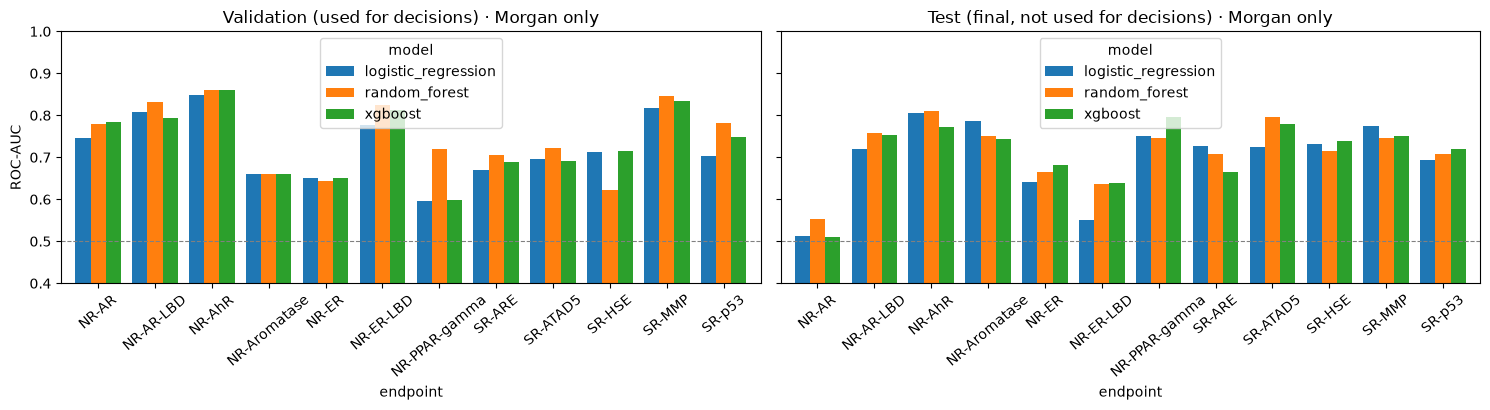

In [13]:
def endpoint_table(split: str, feature_set: str, metric: str) -> pd.DataFrame:
    t = all_metrics.query("split == @split and feature_set == @feature_set").pivot(index="endpoint", columns="model", values=metric).loc[TASKS]
    return t[[m for m in ["logistic_regression", "random_forest", "xgboost"] if m in t.columns]]

counts_col = counts["val"][["n_observed", "n_positive", "n_negative"]]
print("VALIDATION, Morgan fingerprints only (counts are validation labels):")
display(show(pd.concat({"ROC-AUC": endpoint_table("val", "morgan", "roc_auc"), "PR-AUC": endpoint_table("val", "morgan", "pr_auc"), "val labels": counts_col}, axis=1)))

fig, axes = plt.subplots(1, 2, figsize=(15, 4.2), sharey=True)
for ax, split in zip(axes, ["val", "test"]):
    endpoint_table(split, "morgan", "roc_auc").plot.bar(ax=ax, width=0.8)
    ax.axhline(0.5, color="grey", lw=0.8, ls="--"); ax.set_ylim(0.4, 1.0)
    ax.set_title(f"{'Validation (used for decisions)' if split == 'val' else 'Test (final, not used for decisions)'} · Morgan only")
    ax.set_ylabel("ROC-AUC"); ax.tick_params(axis="x", rotation=40)
plt.tight_layout(); fig.savefig(comparison_dir / "figures" / "morgan_roc_auc_by_endpoint.png", dpi=150); plt.show()

In [14]:
print("TEST, Morgan fingerprints only (reported after all choices were frozen; counts are test labels):")
show(pd.concat({"ROC-AUC": endpoint_table("test", "morgan", "roc_auc"), "PR-AUC": endpoint_table("test", "morgan", "pr_auc"), "test labels": counts["test"][["n_observed", "n_positive", "n_negative"]]}, axis=1))

TEST, Morgan fingerprints only (reported after all choices were frozen; counts are test labels):


ROC-AUC                                    PR-AUC                       test labels                      
              logistic_regression random_forest xgboost logistic_regression random_forest xgboost  n_observed n_positive n_negative
endpoint                                                                                                                           
NR-AR                       0.514         0.552   0.509               0.021         0.025   0.025         691         14        677
NR-AR-LBD                   0.719         0.758   0.754               0.082         0.245   0.157         598         12        586
NR-AhR                      0.806         0.811   0.772               0.534         0.561   0.526         582        110        472
NR-Aromatase                0.785         0.751   0.744               0.379         0.451   0.411         490         53        437
NR-ER                       0.641         0.664   0.683               0.257         0.306    0.28         537         72        465
NR-ER-LBD                   0.551         0.637   0.638               0.122         0.163   0.167         631         24        607
NR-PPAR-gamma                0.75         0.747   0.797                0.34         0.306   0.289         559         32        527
SR-ARE                      0.728         0.708   0.666               0.464         0.451   0.376         497        120        377
SR-ATAD5                    0.725         0.797   0.778               0.168         0.213   0.154         645         33        612
SR-HSE                      0.731         0.716   0.739                0.29         0.325   0.268         605         55        550
SR-MMP                      0.774         0.746   0.751               0.433          0.44   0.401         465         89        376
SR-p53                      0.694         0.709   0.721               0.238         0.322   0.325         618         75        543

## 9. Feature experiments: all models × all feature sets (validation ROC-AUC)
Rows are endpoints. Columns are model | feature set. **The input features change between columns** (Morgan, descriptors, or both).

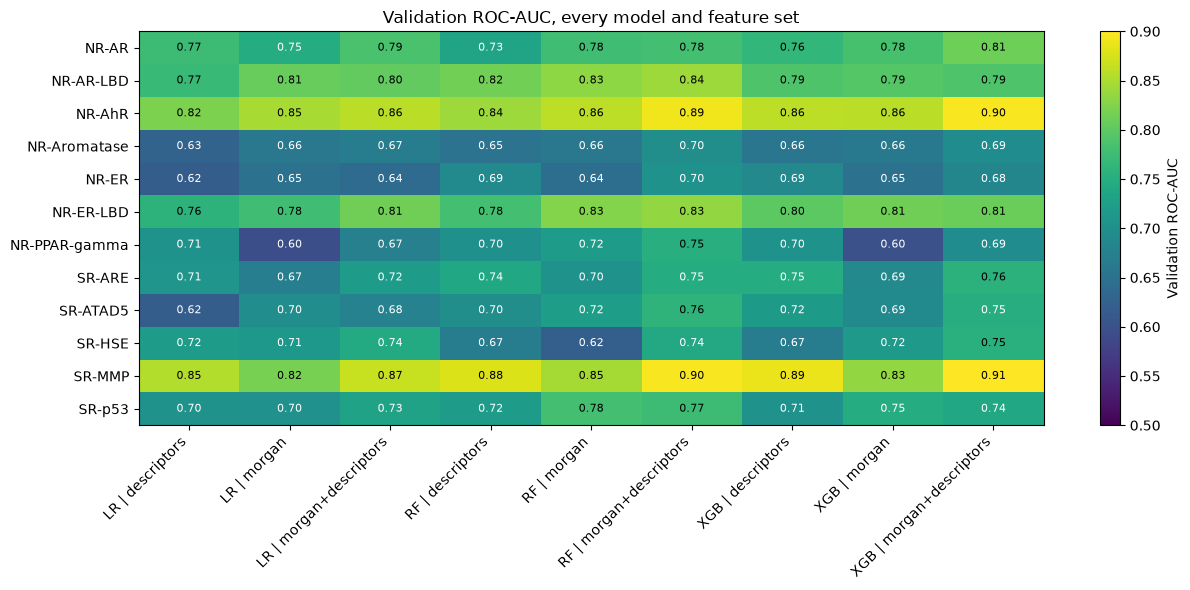

In [15]:
val_grid = all_metrics.query("split == 'val'").pivot(index="endpoint", columns="config", values="roc_auc").loc[TASKS]
fig, ax = plt.subplots(figsize=(1.1 * val_grid.shape[1] + 3, 6))
image = ax.imshow(val_grid.to_numpy(dtype=float), cmap="viridis", vmin=0.5, vmax=0.9, aspect="auto")
ax.set_xticks(range(val_grid.shape[1])); ax.set_xticklabels(val_grid.columns, rotation=45, ha="right")
ax.set_yticks(range(len(TASKS))); ax.set_yticklabels(TASKS)
for i in range(val_grid.shape[0]):
    for j in range(val_grid.shape[1]):
        v = val_grid.iat[i, j]
        ax.text(j, i, "undef." if pd.isna(v) else f"{v:.2f}", ha="center", va="center", fontsize=8, color="white" if (pd.isna(v) or v < 0.75) else "black")
fig.colorbar(image, label="Validation ROC-AUC"); ax.set_title("Validation ROC-AUC, every model and feature set")
plt.tight_layout(); fig.savefig(comparison_dir / "figures" / "validation_roc_auc_heatmap.png", dpi=150); plt.show()

## 10. Model selection on validation, then final test results
**A. One configuration for all endpoints:** for each model family, the feature set with the highest mean validation ROC-AUC. Then the overall best configuration.

In [16]:
val_summary = summary.query("split == 'val'").sort_values("mean_roc_auc", ascending=False)
best_per_family = val_summary.groupby("model", sort=False).head(1)
print("Chosen on VALIDATION (mean over endpoints with a defined metric):")
display(show(best_per_family[["model", "feature_set", "mean_roc_auc", "mean_pr_auc", "endpoints_defined"]]))
chosen = best_per_family.iloc[0]
print(f"Overall best on validation: {chosen.model} with {chosen.feature_set} features (mean val ROC-AUC {chosen.mean_roc_auc:.3f}).")
print("\nFINAL TEST results for each family's chosen configuration (not used for selection):")
test_final = summary.query("split == 'test'").merge(best_per_family[["model", "feature_set"]], on=["model", "feature_set"])
show(test_final[["model", "feature_set", "mean_roc_auc", "mean_pr_auc", "endpoints_defined"]])

Chosen on VALIDATION (mean over endpoints with a defined metric):


,model,feature_set,mean_roc_auc,mean_pr_auc,endpoints_defined
10,random_forest,morgan+descriptors,0.785,0.407,12
16,xgboost,morgan+descriptors,0.774,0.391,12
4,logistic_regression,morgan+descriptors,0.749,0.297,12


Overall best on validation: random_forest with morgan+descriptors features (mean val ROC-AUC 0.785).

FINAL TEST results for each family's chosen configuration (not used for selection):


,model,feature_set,mean_roc_auc,mean_pr_auc,endpoints_defined
0,logistic_regression,morgan+descriptors,0.739,0.269,12
1,random_forest,morgan+descriptors,0.764,0.37,12
2,xgboost,morgan+descriptors,0.755,0.354,12


**B. Best configuration per endpoint, chosen on validation ROC-AUC.** The validation table is used for the choice. The test table only reports how those choices did.

In [17]:
val_rows = all_metrics.query("split == 'val'").dropna(subset=["roc_auc"])
best_val = (val_rows.sort_values(["endpoint", "roc_auc", "pr_auc"], ascending=[True, False, False])
            .groupby("endpoint").head(1).set_index("endpoint").loc[[t for t in TASKS if t in set(val_rows["endpoint"])]])
undefined = [t for t in TASKS if t not in best_val.index]
best_val_table = best_val[["model", "feature_set", "roc_auc", "pr_auc", "n_observed", "n_positive", "n_negative"]].rename(
    columns={"roc_auc": "val_roc_auc", "pr_auc": "val_pr_auc", "n_observed": "val_n_observed", "n_positive": "val_n_positive", "n_negative": "val_n_negative"})
best_val_table.to_csv(comparison_dir / "best_per_endpoint_validation.csv")
print("VALIDATION choice per endpoint" + (f" (no defined validation metric for: {undefined})" if undefined else ""))
display(show(best_val_table))

test_rows = all_metrics.query("split == 'test'").set_index(["endpoint", "model", "feature_set"])
best_test_table = pd.DataFrame([{"endpoint": t, "model": r.model, "feature_set": r.feature_set,
                                 **test_rows.loc[(t, r.model, r.feature_set), ["roc_auc", "pr_auc", "n_observed", "n_positive", "n_negative"]].to_dict()}
                                for t, r in best_val.iterrows()]).set_index("endpoint").rename(
    columns={"roc_auc": "test_roc_auc", "pr_auc": "test_pr_auc", "n_observed": "test_n_observed", "n_positive": "test_n_positive", "n_negative": "test_n_negative"})
best_test_table = best_test_table.astype({c: int for c in ["test_n_observed", "test_n_positive", "test_n_negative"]})
best_test_table.to_csv(comparison_dir / "best_per_endpoint_test_of_validation_choice.csv")
print("FINAL TEST results of those validation choices (reporting only):")
display(show(best_test_table))
print("Validation winners by model:", best_val_table["model"].value_counts().to_dict())

VALIDATION choice per endpoint


,model,feature_set,val_roc_auc,val_pr_auc,val_n_observed,val_n_positive,val_n_negative
endpoint,,,,,,,
NR-AR,xgboost,morgan+descriptors,0.811,0.581,710,42,668
NR-AR-LBD,random_forest,morgan+descriptors,0.841,0.533,623,27,596
NR-AhR,xgboost,morgan+descriptors,0.897,0.562,626,74,552
NR-Aromatase,random_forest,morgan+descriptors,0.697,0.165,512,36,476
NR-ER,random_forest,morgan+descriptors,0.704,0.408,536,65,471
NR-ER-LBD,random_forest,morgan+descriptors,0.835,0.485,659,23,636
NR-PPAR-gamma,random_forest,morgan+descriptors,0.75,0.12,560,24,536
SR-ARE,xgboost,morgan+descriptors,0.758,0.544,449,110,339
SR-ATAD5,random_forest,morgan+descriptors,0.76,0.184,659,33,626


FINAL TEST results of those validation choices (reporting only):


,model,feature_set,test_roc_auc,test_pr_auc,test_n_observed,test_n_positive,test_n_negative
endpoint,,,,,,,
NR-AR,xgboost,morgan+descriptors,0.574,0.027,691,14,677
NR-AR-LBD,random_forest,morgan+descriptors,0.795,0.231,598,12,586
NR-AhR,xgboost,morgan+descriptors,0.833,0.613,582,110,472
NR-Aromatase,random_forest,morgan+descriptors,0.826,0.518,490,53,437
NR-ER,random_forest,morgan+descriptors,0.738,0.395,537,72,465
NR-ER-LBD,random_forest,morgan+descriptors,0.717,0.212,631,24,607
NR-PPAR-gamma,random_forest,morgan+descriptors,0.796,0.328,559,32,527
SR-ARE,xgboost,morgan+descriptors,0.786,0.568,497,120,377
SR-ATAD5,random_forest,morgan+descriptors,0.826,0.295,645,33,612


Validation winners by model: {'random_forest': 7, 'xgboost': 5}


## 11. Class imbalance and why performance varies
A random ranking scores ROC-AUC = 0.5 and PR-AUC ≈ **the positive rate**, so PR-AUC must be read against each endpoint's prevalence. The checks below are computed from the results. With only 12 endpoints, any correlation is weak evidence.

,train_n_positive,train_positive_rate,val_positive_rate,test_n_positive,random_forest_val_roc_auc,random_forest_val_pr_auc,random_forest_val_pr_lift,xgboost_val_roc_auc,xgboost_val_pr_auc,xgboost_val_pr_lift,logistic_regression_val_roc_auc,logistic_regression_val_pr_auc,logistic_regression_val_pr_lift
endpoint,,,,,,,,,,,,,
NR-AR,248,0.043,0.059,14,0.781,0.596,10.079,0.811,0.581,9.83,0.785,0.556,9.392
NR-AR-LBD,196,0.036,0.043,12,0.841,0.533,12.297,0.79,0.465,10.727,0.804,0.348,8.02
NR-AhR,579,0.111,0.118,110,0.891,0.57,4.824,0.897,0.562,4.752,0.859,0.411,3.474
NR-Aromatase,197,0.042,0.07,53,0.697,0.165,2.353,0.694,0.127,1.8,0.67,0.12,1.704
NR-ER,643,0.128,0.121,72,0.704,0.408,3.367,0.683,0.401,3.305,0.639,0.236,1.944
NR-ER-LBD,296,0.053,0.035,24,0.835,0.485,13.882,0.81,0.447,12.796,0.813,0.201,5.769
NR-PPAR-gamma,129,0.025,0.043,32,0.75,0.12,2.798,0.694,0.096,2.247,0.675,0.104,2.427
SR-ARE,685,0.143,0.245,120,0.748,0.499,2.038,0.758,0.544,2.222,0.721,0.398,1.623
SR-ATAD5,195,0.034,0.05,33,0.76,0.184,3.682,0.749,0.166,3.313,0.677,0.145,2.903


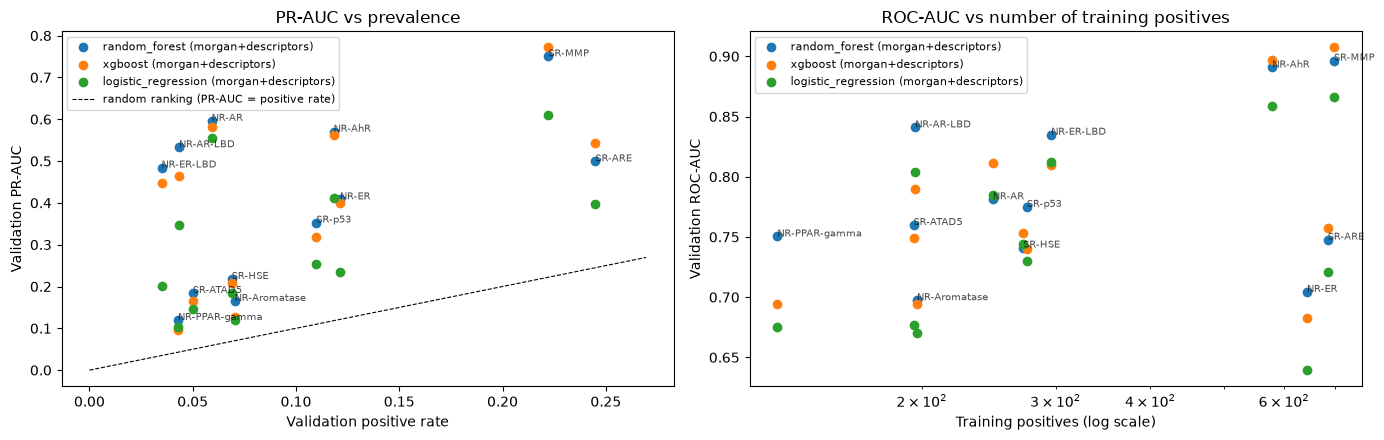

random_forest: Spearman correlation, training positives vs validation ROC-AUC = 0.21 (p = 0.51, n = 12 endpoints)
xgboost: Spearman correlation, training positives vs validation ROC-AUC = 0.38 (p = 0.23, n = 12 endpoints)
logistic_regression: Spearman correlation, training positives vs validation ROC-AUC = 0.36 (p = 0.26, n = 12 endpoints)


In [18]:
best_cfg = {m: fs for m, fs in zip(best_per_family["model"], best_per_family["feature_set"])}
rows = []
for t in TASKS:
    row = {"endpoint": t, "train_n_positive": counts.loc[t, ("train", "n_positive")],
           "train_positive_rate": counts.loc[t, ("train", "n_positive")] / counts.loc[t, ("train", "n_observed")],
           "val_positive_rate": counts.loc[t, ("val", "n_positive")] / counts.loc[t, ("val", "n_observed")],
           "test_n_positive": counts.loc[t, ("test", "n_positive")]}
    for m, fs in best_cfg.items():
        r = all_metrics.query("split == 'val' and model == @m and feature_set == @fs and endpoint == @t").iloc[0]
        row[f"{m}_val_roc_auc"], row[f"{m}_val_pr_auc"] = r.roc_auc, r.pr_auc
        row[f"{m}_val_pr_lift"] = r.pr_auc / row["val_positive_rate"]
    rows.append(row)
imbalance = pd.DataFrame(rows).set_index("endpoint")
imbalance.to_csv(comparison_dir / "imbalance_vs_performance.csv")
display(show(imbalance))

fig, axes = plt.subplots(1, 2, figsize=(14, 4.5))
for m, fs in best_cfg.items():
    axes[0].scatter(imbalance["val_positive_rate"], imbalance[f"{m}_val_pr_auc"], label=f"{m} ({fs})")
    axes[1].scatter(imbalance["train_n_positive"], imbalance[f"{m}_val_roc_auc"], label=f"{m} ({fs})")
lim = imbalance["val_positive_rate"].max() * 1.1
axes[0].plot([0, lim], [0, lim], "k--", lw=0.8, label="random ranking (PR-AUC = positive rate)")
axes[0].set_xlabel("Validation positive rate"); axes[0].set_ylabel("Validation PR-AUC"); axes[0].legend(fontsize=8)
axes[1].set_xscale("log"); axes[1].set_xlabel("Training positives (log scale)"); axes[1].set_ylabel("Validation ROC-AUC"); axes[1].legend(fontsize=8)
for ax, txt in zip(axes, ["PR-AUC vs prevalence", "ROC-AUC vs number of training positives"]):
    for t in TASKS:
        x = imbalance.loc[t, "val_positive_rate"] if ax is axes[0] else imbalance.loc[t, "train_n_positive"]
        y = imbalance.loc[t, f"{best_per_family.iloc[0].model}_val_pr_auc" if ax is axes[0] else f"{best_per_family.iloc[0].model}_val_roc_auc"]
        ax.annotate(t, (x, y), fontsize=7, alpha=0.7)
    ax.set_title(txt)
plt.tight_layout(); fig.savefig(comparison_dir / "figures" / "class_imbalance.png", dpi=150); plt.show()

for m in best_cfg:
    rho, p = spearmanr(imbalance["train_n_positive"], imbalance[f"{m}_val_roc_auc"], nan_policy="omit")
    print(f"{m}: Spearman correlation, training positives vs validation ROC-AUC = {rho:.2f} (p = {p:.2f}, n = 12 endpoints)")

In [19]:
# Overfitting check: training vs validation ROC-AUC (Morgan features)
gap = pd.concat([lr_train.query("feature_set == 'morgan'")[["model", "endpoint", "split", "roc_auc"]],
                 all_metrics.query("feature_set == 'morgan' and model != 'logistic_regression'")[["model", "endpoint", "split", "roc_auc"]],
                 lr_metrics.query("feature_set == 'morgan'")[["model", "endpoint", "split", "roc_auc"]]])
gap = gap.groupby(["model", "split"])["roc_auc"].mean().unstack()[["train", "val", "test"]]
print("Mean ROC-AUC over endpoints, Morgan features (train is optimistic by construction):")
show(gap)

Mean ROC-AUC over endpoints, Morgan features (train is optimistic by construction):


split,train,val,test
model,,,
logistic_regression,0.899,0.724,0.702
random_forest,0.988,0.75,0.716
xgboost,0.932,0.737,0.712


### Why performance varies between endpoints and models
These are possible explanations. Compare them with the tables above instead of taking any as proven:
* **Few positives.** Some endpoints have very few actives, especially in test (see `test_n_positive`). A handful of molecules can move ROC-AUC a lot, so those test AUCs are noisy.
* **Imbalance and PR-AUC.** PR-AUC depends on prevalence, so compare it with the positive rate (`pr_lift` above), not across endpoints directly.
* **Scaffold split.** Validation and test contain chemotypes (ring systems) absent from training, and every acyclic molecule sits in train. Models must generalise to new scaffolds, which is harder than a random split.
* **Different biology per assay.** Each endpoint is a different receptor or stress pathway. Some may depend on local substructures (well captured by fingerprints), others on global properties (descriptors).
* **Model capacity.** Trees can fit training data almost perfectly (see the train vs validation gap). Logistic Regression is a linear model on the same bits. Which bias suits an endpoint is an empirical question. These results come from one split and one seed, with no confidence intervals.

## 12. Viva notes: Random Forest, boosting and class imbalance
**Decision tree.** A tree repeatedly splits the molecules on one feature (for example "bit 1380 is 1" or "TPSA ≤ 40"). It picks the split that most reduces impurity. Gini impurity for a node is 1 − p₁² − p₀², where p₁ is the share of actives. A leaf's probability estimate is the share of actives in that leaf.

**Random Forest (bagging).** It trains many deep trees, each on a bootstrap sample of the molecules, and lets each split consider only a random subset of features (`max_features="sqrt"`, about 45 of 2048 bits). Averaging many decorrelated, high-variance trees reduces variance: p(x) = (1/T) Σ_t p_t(x). `min_samples_leaf` limits how small a leaf can be (a smoother, more regularised forest).

**Gradient boosting (XGBoost).** It builds trees **sequentially**. Each new tree fits the gradient of the log-loss with respect to the current prediction, i.e. it corrects the remaining errors. The model is a sum: F(x) = Σ_m η · f_m(x), with p(x) = σ(F(x)). The learning rate η shrinks each step, `max_depth` limits interactions per tree, and `n_estimators` sets the number of steps. Subsampling rows and columns plus L2 leaf regularisation (`reg_lambda`) curb overfitting. Bagging mainly reduces variance; boosting mainly reduces bias.

**Class imbalance.** Most endpoints have about 3–16% actives, so an unweighted model can lower its loss mostly by predicting "inactive".
* RF `class_weight="balanced_subsample"` reweights each tree's bootstrap sample, so both classes contribute equally to impurity.
* XGBoost `scale_pos_weight = n_negative / n_positive` multiplies the gradient of every active molecule.
* Weighting changes the probability scale (it makes predictions less calibrated) and may or may not improve **ranking**. That is why it was a tuned option, not assumed to help. The chosen value per endpoint is in the `params` column.
* ROC-AUC measures ranking and is unaffected by prevalence. PR-AUC focuses on the actives and its random baseline equals the prevalence.

**Fair evaluation.** Every model uses the same scaffold split, the same feature files, observed labels only, one metric function, settings chosen on validation, and the test set used once at the end. The final models are fitted on train only, so validation scores remain an honest record of how settings were chosen.

## 13. Sanity checks (all should print OK)

In [20]:
# 1. Probability outputs have the right shape and rows follow the split files' mol_ids
for (m, fs), r in results.items():
    for s in SPLITS:
        assert r["probs"][s].shape == (len(splits[s]), len(TASKS))
        pred = r["predictions"][s]
        assert len(pred) == len(splits[s]) * len(TASKS)
        assert pred["mol_id"].iloc[::len(TASKS)].tolist() == splits[s]["mol_id"].tolist()
        trained = [t for t in TASKS if r["info"][t]["status"] != "skipped_single_class_train"]
        assert pred[pred["endpoint"].isin(trained)]["y_prob"].between(0, 1).all()
print("OK 1: probability shapes and row-to-ID alignment")

# 2. Missing labels were excluded from every endpoint's training data
for (m, fs), r in results.items():
    for t in TASKS:
        if r["info"][t]["status"] != "skipped_single_class_train":
            assert r["info"][t]["n_rows_fitted"] == counts.loc[t, ("train", "n_observed")], (m, fs, t)
    for s in SPLITS:
        assert int(r["predictions"][s]["y_true"].isna().sum()) == int(counts[s]["n_missing"].sum())
print("OK 2: each endpoint was fitted on exactly its observed training labels; NaN labels kept as NaN")

# 3. Single-class endpoints: checked on synthetic data in section 5 (skip + fallback, run completed)
print("OK 3: single-class handling verified by the self-test before training")

# 4. Saved models load and reproduce the saved predictions
for (m, fs), r in results.items():
    folder = MODELS_DIR / m / FOLDER[fs]
    manifest = json.loads((folder / "manifest.json").read_text())
    for t in TASKS:
        file = manifest["endpoint_models"][t]["model_file"]
        if file:
            reloaded = MODELS[m]["load"](folder / file)
            diff = np.abs(reloaded.predict_proba(features[fs]["test"].X)[:, 1] - r["probs"]["test"][:, TASKS.index(t)]).max()
            assert diff < 1e-6, (m, fs, t, diff)
print("OK 4: every saved model reloads and reproduces its test probabilities")

OK 1: probability shapes and row-to-ID alignment
OK 2: each endpoint was fitted on exactly its observed training labels; NaN labels kept as NaN
OK 3: single-class handling verified by the self-test before training


OK 4: every saved model reloads and reproduces its test probabilities


## 14. Save and download
Two zips are created, because Random Forest models are large:
* `member3_results.zip` (small) contains:
  * `results/random_forest/rf_metrics.csv`, `rf_tuning_log.csv`, `predictions/rf_<feature_set>_<split>.csv`
  * the same for `results/xgboost/xgb_*`
  * `results/comparison/` (all-model metrics, summary, per-endpoint choices, figures)
  * the model manifests
* `member3_models.zip` (large) contains `models/random_forest/<feature_set>/<ENDPOINT>.joblib` and `models/xgboost/<feature_set>/<ENDPOINT>.json`

**Metrics CSV columns:** `model, feature_set, endpoint, split, n_observed, n_positive, n_negative, roc_auc, pr_auc, status, selection_metric, params`. `roc_auc` and `pr_auc` are empty when only one class is observed (undefined).

**Prediction CSV columns:** `model, feature_set, split, mol_id, endpoint, y_true, y_prob`. These are the same columns as Member 2's files, and `y_true` is empty where the label is missing.

In [21]:
for folder in MODELS_DIR.glob("*/*"):
    target = RESULTS_DIR / "model_manifests" / folder.parent.name / folder.name
    target.mkdir(parents=True, exist_ok=True)
    shutil.copy(folder / "manifest.json", target / "manifest.json")
results_zip = shutil.make_archive("member3_results", "zip", ".", RESULTS_DIR.name)
models_zip = shutil.make_archive("member3_models", "zip", ".", MODELS_DIR.name)
for z in (results_zip, models_zip):
    print(f"{z}: {os.path.getsize(z) / 1e6:.1f} MB")

DOWNLOAD_RESULTS, DOWNLOAD_MODELS = True, False      # the models zip can be several hundred MB
if IN_COLAB and DOWNLOAD_RESULTS:
    colab_files.download(results_zip)
if IN_COLAB and DOWNLOAD_MODELS:
    colab_files.download(models_zip)

./member3_results.zip: 1.8 MB
./member3_models.zip: 147.4 MB
